# PSV PROJECT

This is the first notebook which will be using EfficientNet pre-trained model. The data of this project is on the folder raw- images and the tabular data is on pandas labeled-dataset.csv
First we need to create virtual enviroment, in this case is called  'nahiavenv' 
Afterwards, we need to download all the needed libraries. Such as :tensorflow, pandas, scikit-learn, pillow, matplotlib

In [4]:
import os
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input

### Loading and Preparing the Dataset

The first step in the pipeline is loading and preparing the dataset for training. The dataset consists of images collected from Instagram posts and manually labelled into predefined categories. The image paths and corresponding labels are stored in a CSV file.

In [5]:
df = pd.read_csv("labeled_dataset.csv")
df.head()

,image_path,shortcode,likes,timestamp,caption,comment_count,category
0,DMhd4aiMXhj_0.jpg,DMhd4aiMXhj,10223,2025-07-25 09:47:28,"#OttenInnovationCup, het eerste podium voor gr...",17,graphic_post
1,DMhd4aiMXhj_1.jpg,DMhd4aiMXhj,10223,2025-07-25 09:47:28,"#OttenInnovationCup, het eerste podium voor gr...",17,graphic_post
2,DMhd4aiMXhj_2.jpg,DMhd4aiMXhj,10223,2025-07-25 09:47:28,"#OttenInnovationCup, het eerste podium voor gr...",17,graphic_post
3,DMhd4aiMXhj_3.jpg,DMhd4aiMXhj,10223,2025-07-25 09:47:28,"#OttenInnovationCup, het eerste podium voor gr...",17,graphic_post
4,DMj9VcQs0SB_0.jpg,DMj9VcQs0SB,13198,2025-07-26 09:00:00,Provisional squad numbers? We’ve got you. 👕,66,graphic_post


Before training the model, several preprocessing steps are applied. First, images without labels or invalid file paths are removed to ensure data consistency.

In [6]:
df = df[df["category"] != "behind_scenes"]
import os

to_remove = ["behind_scenes"]

files_to_delete = df[df["category"].isin(to_remove)]["image_path"]

for path in files_to_delete:
    if os.path.exists(path):
        os.remove(path)

In [7]:
df = df.dropna(subset=["category"])
print(df["category"].value_counts())

category
graphic_post       196
player_portrait    137
fans_stadium        44
match_action        43
celebration         22
training            17
commercial          12
Name: count, dtype: int64


In [8]:

df["image_path"] = "raw_images/" + df["image_path"]

df = df[
    df["image_path"].apply(os.path.exists)
].copy()


Now, we need to change the string of the categories to numbers since the model does not understand the strings.

In [9]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["label"] = le.fit_transform(df["category"])

### Train/Validation/Test

To properly evaluate the model, the dataset is split into three parts: training, validation, and testing. The training set is used to learn, the validation set helps tune the model, and the test set is used for final evaluation on unseen data.

In [10]:
from sklearn.model_selection import train_test_split

train_val_df, test_df = train_test_split(
    df,
    test_size=0.15,
    stratify=df["label"],
    random_state=42
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.2,
    stratify=train_val_df["label"],
    random_state=42
)

### Data Pipeline
Build efficient `tf.data` pipelines for each split. Images are read from disk, decoded,
resized to 224×224, and preprocessed for EfficientNet.

In [11]:
IMG_SIZE = 224
BATCH_SIZE = 16

from tensorflow.keras.applications.efficientnet import preprocess_input

def process_image(image_path, label):
    try:
        image = tf.io.read_file(image_path)
        image = tf.image.decode_image(image, channels=3)
        
        # Check if image has a shape (valid image)
        if len(image.shape) < 2:
            raise ValueError("Invalid image shape")
        
        image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
        image = preprocess_input(image)
        return image, label
    except Exception as e:
        # Return a blank image on error
        blank_image = tf.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32)
        return blank_image, label


### Create the dataloaders

After splitting the dataset, we create separate tensor flow datasets.

In [12]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (
        train_df["image_path"].values,
        train_df["label"].values
    )
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (
        val_df["image_path"].values,
        val_df["label"].values
    )
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (
        test_df["image_path"].values,
        test_df["label"].values
    )
)

In [13]:
train_ds = (
    train_ds
    .map(process_image)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    val_ds
    .map(process_image)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    test_ds
    .map(process_image)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

### Data Augmentation
Apply random horizontal flips, rotations, and zoom during training to improve
generalization and reduce overfitting.

In [14]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.1),

    layers.RandomZoom(0.1),

])

### Transfer Learning with EfficientNetB0

Because the dataset is relatively small, transfer learning was used instead of training a convolutional neural network from scratch. EfficientNetB0 pre-trained on ImageNet was selected due to its balance between performance and computational efficiency.

In [15]:
from tensorflow.keras.applications import EfficientNetB0

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

The convolutional base of the model was initially frozen, meaning that only the final classification layers were trained on the custom dataset. This approach reduces overfitting and allows the model to leverage previously learned visual features.

In [16]:
from tensorflow.keras import models

model = models.Sequential([

    data_augmentation,
    
    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(
        len(le.classes_),
        activation="softmax"
    )

])

### Compilation 

Compile with `sparse_categorical_crossentropy` loss, suitable for integer-encoded
single-label classification. Accuracy is tracked as the main metric.

In [17]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Training
Train for up to 30 epochs with early stopping monitoring `val_loss`.
Best weights are automatically restored if validation performance degrades.

In [18]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [19]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping]
)

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 41s 698ms/step - accuracy: 0.3187 - loss: 1.6982 - val_accuracy: 0.4250 - val_loss: 1.5404
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 464ms/step - accuracy: 0.4156 - loss: 1.5563 - val_accuracy: 0.4250 - val_loss: 1.5263
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 501ms/step - accuracy: 0.4062 - loss: 1.5551 - val_accuracy: 0.4250 - val_loss: 1.5166
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 423ms/step - accuracy: 0.3969 - loss: 1.5474 - val_accuracy: 0.4250 - val_loss: 1.5166
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 424ms/step - accuracy: 0.3750 - loss: 1.5832 - val_accuracy: 0.4250 - val_loss: 1.5181
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 477ms/step - accuracy: 0.4125 - loss: 1.5523 - val_accuracy: 0.4250 - val_loss: 1.5154
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 424ms/step - accuracy: 0.4031 - loss: 1.5720 - val_accuracy: 0.4250 - val_loss: 1.5214
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 466ms/step - accuracy: 0.4031 - loss: 1.5645 - val_accuracy: 

### Confusion Matrix & Metrics
Evaluate the model on the test set using a confusion matrix and a full classification
report. Predictions are obtained via `argmax` over the softmax output and compared
against the ground truth labels to compute precision, recall, and F1-score per class.

5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 665ms/step


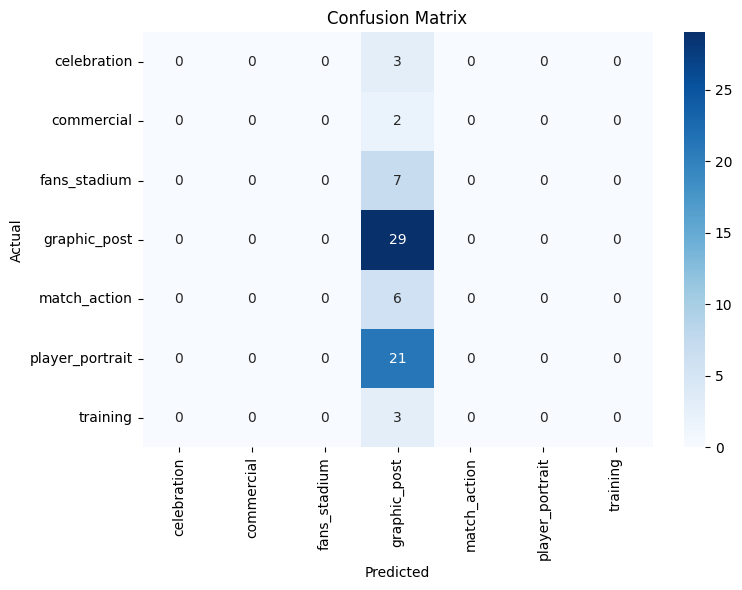

                 precision    recall  f1-score   support

    celebration       0.00      0.00      0.00         3
     commercial       0.00      0.00      0.00         2
   fans_stadium       0.00      0.00      0.00         7
   graphic_post       0.41      1.00      0.58        29
   match_action       0.00      0.00      0.00         6
player_portrait       0.00      0.00      0.00        21
       training       0.00      0.00      0.00         3

       accuracy                           0.41        71
      macro avg       0.06      0.14      0.08        71
   weighted avg       0.17      0.41      0.24        71



c:\Users\Nahia\OneDrive - Office 365 Fontys\ICT\SEMESTER 3\PSV project\nahiavenv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Nahia\OneDrive - Office 365 Fontys\ICT\SEMESTER 3\PSV project\nahiavenv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Nahia\OneDrive - Office 365 Fontys\ICT\SEMESTER 3\PSV project\nahiavenv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted sa

In [20]:
## 📊 10. Evaluation — Confusion Matrix & Metrics
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

# ── Get predictions ──────────────────────────────────────────────────────────
y_pred_probs = model.predict(test_ds)                      # shape: (N, num_classes)
y_pred       = np.argmax(y_pred_probs, axis=1)             # predicted class index

# Ground truth — extract labels from test_ds
y_true = np.concatenate([y for _, y in test_ds], axis=0)

# ── Confusion Matrix ─────────────────────────────────────────────────────────
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# ── Classification Report ────────────────────────────────────────────────────
print(classification_report(y_true, y_pred, target_names=le.classes_))